# Model Selection
Compare, tune and choose the model that will perform best on **new** data, not just on the training set.
- Compare algorithms and tune hyper-parameters
- Evaluate on a validation sample (holdout or cross-validation)
- Balance model quality with interpretability and complexity

Project background: see the [class project intro](../data_science_bootcamp_lecture_1_class_project_intro.md).

## Initialization

In [1]:
import pandas as pd
import numpy as np
import os
import rich

In [2]:
version_tag = "dev"

## Load Data

In [3]:
input_folder = "../.local/analysis_pipeline/data_exploration"
model_data = pd.read_parquet(f"{input_folder}/model_data_{version_tag}.parquet")
print(model_data.shape)

(15000, 29)


## Build Model
This is the base model of our project

In [4]:
# Compute the capped claim amount per exposure
model_data['claim_amt_capped_per_exposure'] = model_data['claim_amt_capped'] / model_data['exposure']

In [5]:
# Define the list of predictors
# Predictor list, grouped by theme
veh_pred_lst = ['veh_value', 'veh_body', 'veh_age', 'engine_type', 'max_power', 'veh_color']
policy_pred_lst = ['gender', 'agecat', 'e_bill' ]
driving_behavior_pred_lst = ['area', 'time_of_week_driven', 'time_driven']
demo_pred_lst = ['marital_status', 'low_education_ind', 'credit_score', 'driving_history_score']
pred_lst = veh_pred_lst + policy_pred_lst + driving_behavior_pred_lst + demo_pred_lst

# Predictors to plot in the notebook, in this order
show_vars = ['veh_value', 'veh_body', 'credit_score', 'driving_history_score', 'low_education_ind']
# pred_lst = ['engine_type', 'gender', 'credit_score', 'veh_age', 'agecat', 'area']

# Split into training and validation samples
train_data = model_data.loc[model_data['sample'] == '1|bld'].copy()
val_data = model_data.loc[model_data['sample'] == '2|val'].copy()
rich.print( train_data.shape, val_data.shape )
train_data.head(5)

(11204, 30)
(3796, 30)

,id,fold,sample,veh_value,exposure,veh_body,veh_age,gender,area,agecat,...,low_education_ind,clm,claim_cnt,claim_amt,veh_cnt,data_segment,claim_sev,claim_sev_capped,claim_amt_capped,claim_amt_capped_per_exposure
0,1,2,1|bld,5.80,0.362191,SUV,2,F,B,1,...,0.0,1,1,2023.198184,1,1|model,2023.198184,2023.198184,2023.198184,5585.998969
1,2,3,1|bld,5.67,0.632068,STNWG,4,F,A,2,...,0.0,1,1,3600.172234,1,1|model,3600.172234,3600.172234,3600.172234,5695.859540
2,3,1,1|bld,5.90,0.367460,SEDAN,2,F,C,2,...,0.0,1,1,2021.144067,1,1|model,2021.144067,2021.144067,2021.144067,5500.307127
3,4,2,1|bld,4.79,0.802184,STNWG,3,M,B,4,...,0.0,1,1,4006.845492,1,1|model,4006.845492,4006.845492,4006.845492,4994.920513
4,5,2,1|bld,6.68,0.485009,SEDAN,3,M,C,1,...,0.0,1,1,2542.953931,1,1|model,2542.953931,2542.953931,2542.953931,5243.106060


In [6]:
# XGBoost Tweedie Regression with Cross-Validation Early Stopping and Native Categorical Support
import xgboost as xgb

# Define features and target
y = train_data['claim_amt_capped_per_exposure']
X = train_data[pred_lst].copy()
# weights = train_data['exposure']  # Assuming exposure is in years, convert to months

# Convert object columns to pandas Categorical dtype for XGBoost native categorical support
for col in pred_lst:
    if X[col].dtype == 'object':
        X[col] = X[col].astype('category')

# XGBoost DMatrix with offset
dtrain = xgb.DMatrix(X, label=y, enable_categorical=True)

# # Compute offset (log of exposure, or any other offset variable)
# offset = np.log(train_data['exposure'])
# dtrain.set_base_margin(offset)

# Define XGBoost parameters for Tweedie regression
params = {
    'objective': 'reg:tweedie',         # Tweedie regression objective
    'tweedie_variance_power': 1.5,      # Tweedie power (1=Poisson, 2=Gamma, 1<p<2 for insurance)
    'learning_rate': 0.01,              # Step size shrinkage (smaller = more robust, slower learning)
    'max_depth': 5,                     # Maximum tree depth (controls model complexity)
    'min_child_weight': 100,            # Minimum sum of instance weight (hessian) needed in a child (min samples per leaf, set for 45,300 samples)
    'subsample': 0.8,                   # Fraction of samples used per tree (prevents overfitting)
    'colsample_bytree': 0.8,            # Fraction of features used per tree (prevents overfitting)
    'lambda': 1.0,                      # L2 regularization term (prevents overfitting)
    'alpha': 0.0,                       # L1 regularization term (prevents overfitting)
    'nthread': -1,                      # Use all CPU cores
    'seed': 42                          # Random seed for reproducibility
}

# Cross-validation with early stopping
cv_results = xgb.cv(
    params,
    dtrain,
    num_boost_round=5000,
    nfold=5,  # 5-fold cross-validation
    metrics='rmse',  # or another appropriate metric
    early_stopping_rounds=50,
    seed=42,
    verbose_eval=50
 )

# The best number of boosting rounds is:
best_num_boost_round = len(cv_results)
print(f"Best num_boost_round from CV: {best_num_boost_round}")

# Train final model on all data using best_num_boost_round
model = xgb.train(
    params,
    dtrain,
    # num_boost_round=500
    num_boost_round=best_num_boost_round
 )

[0]	train-rmse:3932.63586+88.89724	test-rmse:3919.74248+350.22662


[50]	train-rmse:3889.97523+87.57081	test-rmse:3908.12175+353.58335


[100]	train-rmse:3855.63410+86.84389	test-rmse:3903.25235+355.21433


[150]	train-rmse:3824.44930+86.03923	test-rmse:3900.68018+356.82161


[200]	train-rmse:3795.36755+84.30903	test-rmse:3898.90605+358.26321


[250]	train-rmse:3767.74359+84.12319	test-rmse:3897.94085+358.91929


[300]	train-rmse:3741.73041+83.58660	test-rmse:3897.13153+359.63988


[349]	train-rmse:3717.71637+82.21969	test-rmse:3897.68411+359.66392


Best num_boost_round from CV: 301


1.6070781970666297


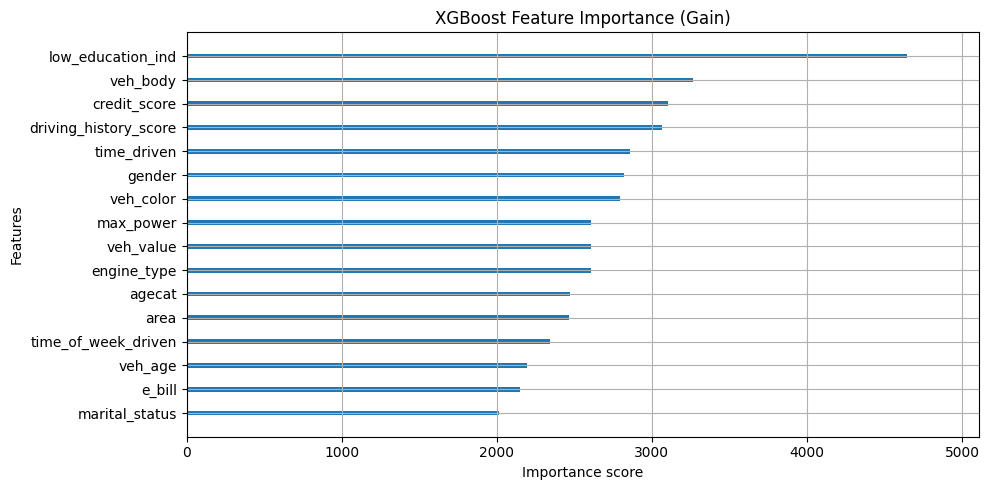

In [7]:
# Model Fitting Score and Prediction ---
# Prepare train and validation data for prediction
X_train = train_data[pred_lst].copy()
X_val = val_data[pred_lst].copy()

# Convert object columns to category for both sets
for col in pred_lst:
    if X_train[col].dtype == 'object':
        X_train[col] = X_train[col].astype('category')
    if X_val[col].dtype == 'object':
        X_val[col] = X_val[col].astype('category')

# In-sample fitted values
dtrain_pred = xgb.DMatrix(X_train, enable_categorical=True)
train_pred = model.predict(dtrain_pred)
train_data['pred_per_exposure'] = train_pred 
train_data['pred'] = train_data['pred_per_exposure'] * train_data['exposure']  # Scale by exposure
rescale_factor_2 = train_data['claim_amt_capped'].sum() / train_data['pred'].sum()
print(rescale_factor_2)
train_data['pred_rescale'] = train_data['pred'] * rescale_factor_2

# Out-of-sample prediction on validation set
dval_pred = xgb.DMatrix(X_val, enable_categorical=True)
val_pred = model.predict(dval_pred)
val_data['pred_per_exposure'] = val_pred
val_data['pred'] = val_data['pred_per_exposure'] * val_data['exposure']  # Scale by exposure
val_data['pred_rescale'] = val_data['pred'] * rescale_factor_2

# --- Variable Importance Plot ---
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(10, 5))
xgb.plot_importance(model, ax=ax, importance_type='gain', show_values=False, title='XGBoost Feature Importance (Gain)')
plt.tight_layout()
plt.show()

In [8]:
# Save the base model
output_folder = "../.local/analysis_pipeline/model_selection"
os.makedirs(output_folder, exist_ok=True)
model.save_model(f"{output_folder}/xgb_tweedie_model_{version_tag}.json")

## Model Evaluation
Below please find resources on different model evaluation metrics:
1. Gini coefficient: The Gini coefficient is a statistical measure of inequality, but in the context of the Casualty Actuarial Society (CAS), it is used to evaluate the effectiveness of predictive models, such as those used for insurance ratemaking. In this application, a Gini index measures how well a model's predictions (like for pure premium or risk scores) distinguish between high-risk and low-risk policyholders, with a higher Gini coefficient indicating better model performance. (Source: Search "Gini coefficient Casualty Actuarial Society").
2. https://www.casact.org/sites/default/files/presentation/rpm_2019_presentations_m-4_williams.pdf

### On training data

Top Lift: 4.6099
Gini: 0.7724
R^2: 0.1756
RMSE: 2052.16
MAE: 762.82


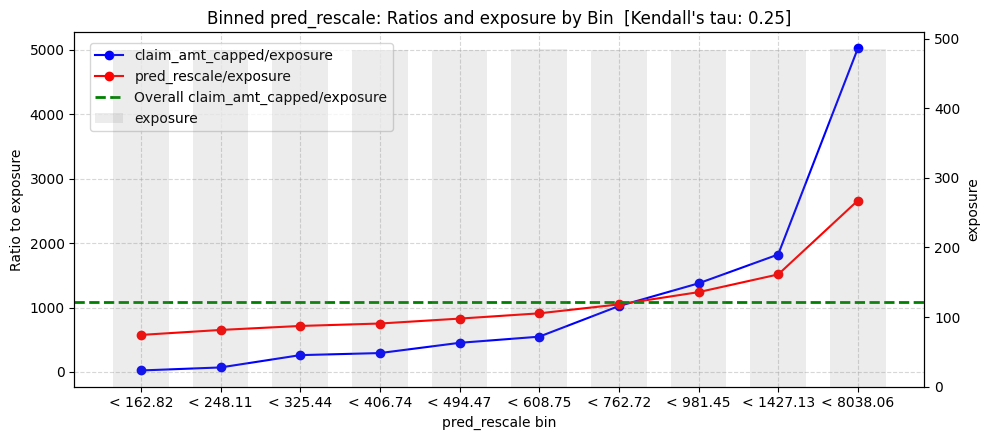

In [9]:
# Ensure the parent directory is in the path for module import
import sys
sys.path.append(os.path.abspath(".."))
from analysis_tool_chest.data_exploration import PredictivenessCheck
from analysis_tool_chest.model_selection import ModelEvaluation

# Select training samples for predictiveness check
data = train_data

# Define variables
exp_var = 'exposure'
pred_var = 'pred_rescale'
var_1 = 'claim_amt_capped'
var_2 = 'pred_rescale'
nbins = 10


# Create and run PredictivenessCheck
pc = PredictivenessCheck(
    df=data,
    pred_var=pred_var,
    exp_var=exp_var,
    var_1=var_1,
    var_2=var_2
)

pc.binning(nbins=nbins)
pc.aggregate()

# Compute top lift
pc.top_lift()

# Compute Gini, R^2, RMSE, and MAE
me = ModelEvaluation(data[var_1], data[var_2])
gini = me.gini()
r2 = me.r2()
rmse = me.rmse()
mae = me.mae()

# Print results
print(f"Top Lift: {pc.top_lift:.4f}")
print(f"Gini: {gini:.4f}")
print(f"R^2: {r2:.4f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
pc.plot(figsize=(10, 4.5))


### On validation data

Top Lift: 1.9736
Gini: 0.5630
R^2: 0.0323
RMSE: 2335.88
MAE: 701.97


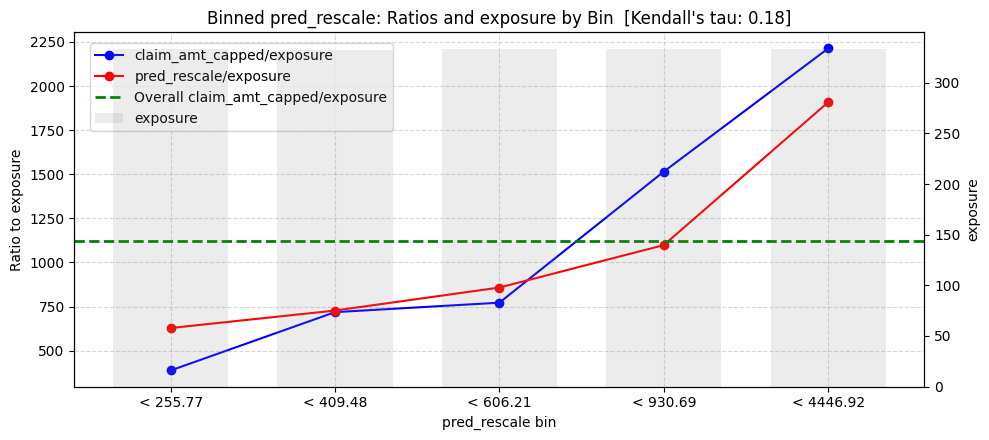

In [10]:
# Select validation sample for predictiveness check
data = val_data

# Define variables
exp_var = 'exposure'
pred_var = 'pred_rescale'
var_1 = 'claim_amt_capped'
var_2 = 'pred_rescale'
nbins = 5


# Create and run PredictivenessCheck
pc = PredictivenessCheck(
    df=data,
    pred_var=pred_var,
    exp_var=exp_var,
    var_1=var_1,
    var_2=var_2
)

pc.binning(nbins=nbins)
pc.aggregate()

# Compute top lift
pc.top_lift()

# Compute Gini, R^2, RMSE, and MAE
var_2 = 'pred'
me = ModelEvaluation(data[var_1], data[var_2])
gini = me.gini()
r2 = me.r2()
rmse = me.rmse()
mae = me.mae()

# Print results
print(f"Top Lift: {pc.top_lift:.4f}")
print(f"Gini: {gini:.4f}")
print(f"R^2: {r2:.4f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
pc.plot(figsize=(10, 4.5))

## Predict Vs Actual Check
### On training data


--- Predictiveness Plot for veh_value ---


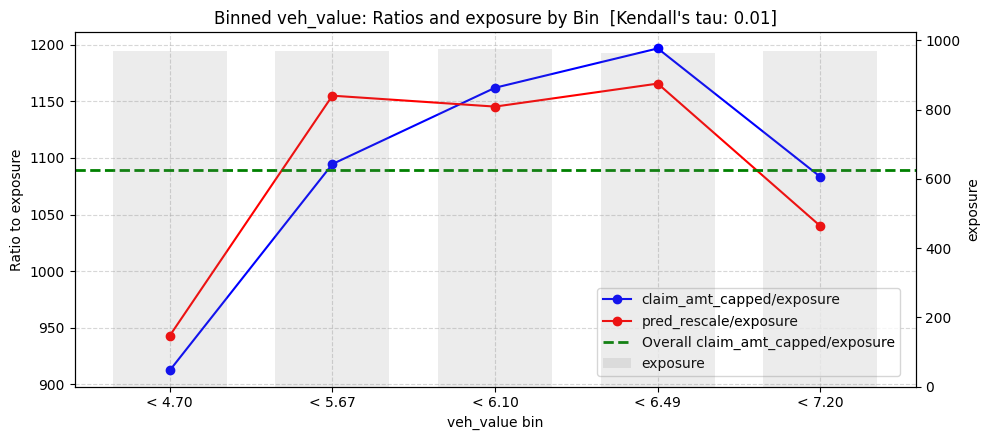


--- Predictiveness Plot for veh_body ---


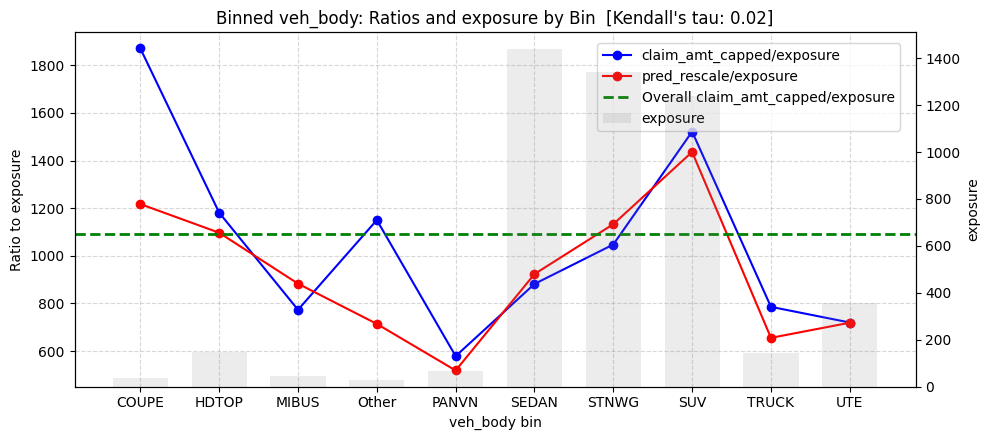


--- Predictiveness Plot for credit_score ---


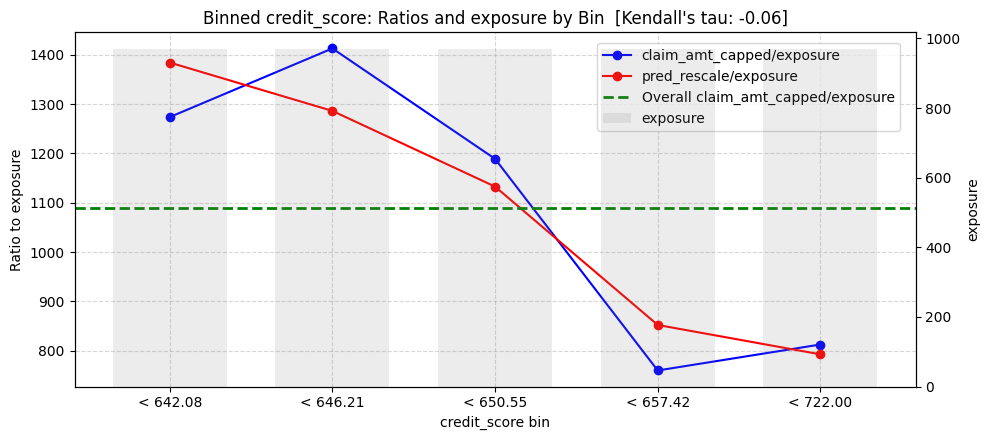


--- Predictiveness Plot for driving_history_score ---


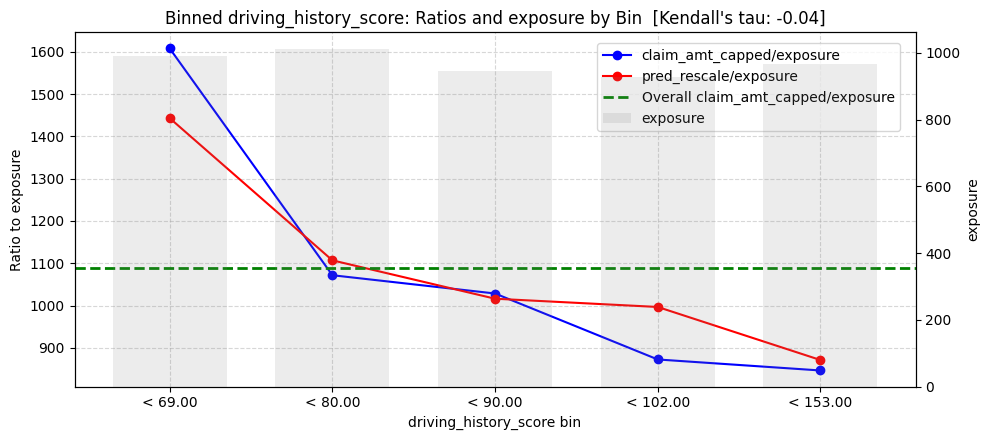


--- Predictiveness Plot for low_education_ind ---


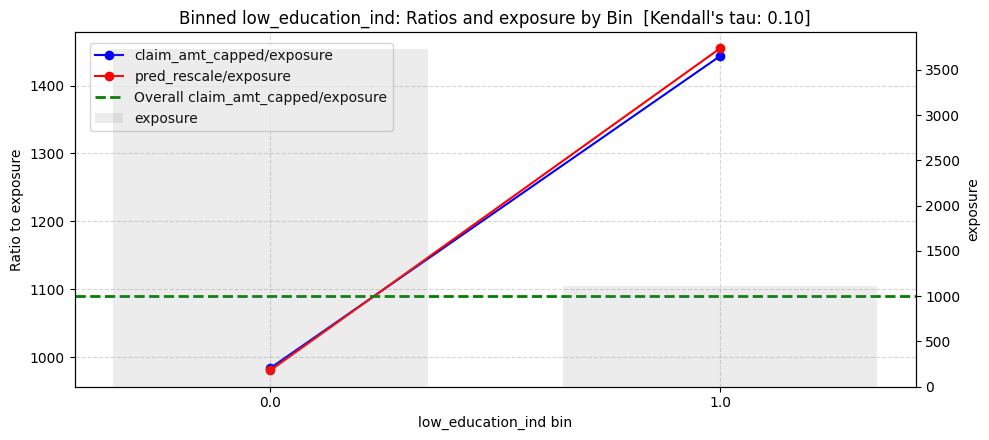


Showing 5 of 16 plots.


In [11]:
from analysis_tool_chest.data_exploration import PredictivenessCheckList

# Predicted vs actual by predictor (training sample)
exp_var = 'exposure' 
var_1 = 'claim_amt_capped'     
var_2 = 'pred_rescale'   
nbins = 5         

# Create and run the PredictivenessCheckList
pcl = PredictivenessCheckList(
    data=train_data,
    pred_var_lst=pred_lst,
    exp_var=exp_var,
    var_1=var_1,
    var_2=var_2,     
    nbins=nbins
)

pcl.run_all()
pcl.plot_all(show_vars=show_vars)

## <span style="color:red"><b><i>Model Selection</i></b></span>

<span style="color:red"><b><i>Task 2: Conduct hyper-parameters tuning on the tree-based model and compare the selected model performance with our base model above. Instead of doing a full panel grid search on all hyper-parameters. Let us consider an interactive hyper-parameter tuning approach to tune two to three hyper-parameters at a time. The benefits are:</i></b></span>

1. <span style="color:red"><b><i>Human judgment and decisions are included.</i></b></span>
2. <span style="color:red"><b><i>Better computational efficiency.</i></b></span>
3. <span style="color:red"><b><i>Hyper-parameter tuning according to their dependencies.</i></b></span>
4. <span style="color:red"><b><i>Better understand hyper-parameters of a tree-based model.</i></b></span>

<span style="color:red"><b><i>For interactive hyper-parameter tuning tutorials, please refer to: 
- https://www.analyticsvidhya.com/blog/2016/02/complete-guide-parameter-tuning-gradient-boosting-gbm-python/.
- https://www.analyticsvidhya.com/blog/2016/03/complete-guide-parameter-tuning-xgboost-with-codes-python/</i></b></span>

<span style="color:red"><b><i>For sample output illustration, please refer to the plots below:</i></b></span>

<div style="display: inline-block; max-width: 100%; box-sizing: border-box; background-color: #f8f8f8; padding: 10px;">
    <p style="color: black;">First, tune learning rate related hyper-parameters.</p>
    <img src="../images/4_grid_search_1.png" alt="Hyper-parameter tuning on learn rate related parameters" style="width:1000px; max-width:100%;">
    <p style="color: black;">Next, tune max depth and minimum rows per node.</p>
    <img src="../images/4_grid_search_2.png" alt="Hyper-parameter tuning on max depth and minimum rows" style="width:1000px; max-width:100%;">
</div>





<span style="color:red"><b><i>Task 3: Examine TabPFN - A Cutting Edge Transformer Based Model on Tabular Data. Specific to-dos: </i></b></span>
1. <span style="color:red"><b><i>Read and summarize the paper: https://arxiv.org/abs/2207.01848.</i></b></span>
2. <span style="color:red"><b><i>Examine TabPFN on our data and compare its performance with the other models built and the base model. Some sample code can be found on TabPFN's GitHub page: https://github.com/PriorLabs/TabPFN.</i></b></span>

<span style="color:red"><b><i>Task 4: Build another type of model (possible candidates: linear model and composite model, please do not build another tree-based models nor deep learning models) and compare its performance with the other models built and the base model above.

<span style="color:red"><b><i>One possible solution: Build a composite model to predict total loss. Specific to-dos: </i></b></span>

1. <span style="color:red"><b><i>Build a frequency model: Poisson Log-likelihood as the object function; 'claim_cnt' column as the target variable.</i></b></span> 
2. <span style="color:red"><b><i>Build a severity model: Gamma Log-likelihood as the object function; 'claim_sev_capped' column as the target variable; Remember to only use policy terms with positive losses.</i></b></span>  
3. <span style="color:red"><b><i>Derive the total loss predictions of each policy term via combining the predictions from the frequency model and severity model.</i></b></span> 
4. <span style="color:red"><b><i>Compare its performance with the other models built and the base model.</i></b></span> 

<span style="color:red"><b><i>Another possible solution: Build a weighted regression method to predict claim cost per exposure or use offset method to predict claim cost per policy </i></b></span>

<span style="color:red"><b><i>Task 5: Conclude the pros and cons of the linear models, tree-based models (decision tree and ensemble tree models), deep learning models (use TabPFN as an example) and any other models you have considered in this project. </i></b></span>